In [ ]:
CW_Data.xlsx

In [5]:
# Import the pandas library
import pandas as pd

# Load your data into a DataFrame
df = pd.read_excel('CW_Data.xlsx')

In [6]:
df.head()

,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_identity_verified,price,minimum_nights,maximum_nights,minimum_minimum_nights,maximum_minimum_nights,...,Subjectivity,review_time_span,recency,average_review_score,city,country,Polarity1,Subjectivity1,continent,host_name
0,2,1.0,1.00,0,1,42,2,730,2,2,...,0.351515,4148,431,4.680000,London,United Kingdom,0.000000,0.000000,Europe,Dee Dee
1,0,1.0,0.25,0,1,175,5,240,5,5,...,0.600000,3894,460,4.788571,London,United Kingdom,0.129420,0.432545,Europe,Sarah
2,0,1.0,0.88,0,1,79,1,29,1,1,...,0.471429,4498,388,4.740000,London,United Kingdom,0.134375,0.275893,Europe,Alina
3,1,1.0,0.41,0,1,150,7,30,7,7,...,0.442500,4879,247,4.844286,Royal Borough of Kensington and Chelsea,United Kingdom,0.000000,0.000000,Europe,Philippa
4,0,0.9,0.75,1,1,46,4,365,2,4,...,0.420000,4447,123,4.665714,London,United Kingdom,0.000000,0.000000,Europe,William


In [7]:
# Function to fill missing values based on the most common value per host
def fill_with_mode(x):
    # Fill missing values with mode. If the mode is not available, use the overall mode for the column.
    return x.fillna(x.mode().iloc[0] if not x.mode().empty else df[x.name].mode().iloc[0])

# Group the data by 'host_name' and apply the function to each group for each column
filled_df = df.groupby('host_name').transform(fill_with_mode)

# If there are still missing values, this means there were no previous data for some hosts to infer from.
# You can decide to fill these remaining missing values with the overall mode for each column.
for column in filled_df.columns:
    filled_df[column].fillna(filled_df[column].mode()[0], inplace=True)

# Now, combine your original df with the filled_df to retain the original non-null values
df.update(filled_df)
df.to_excel('mmmmmm_enc.xlsx', index=False)

In [8]:
import pandas as pd
from sklearn.model_selection import train_test_split
# Assuming df is your loaded DataFrame with the data
# df = pd.read_csv('path_to_your_data.csv') # or any other way you have loaded your data

# Split the dataset into 70% training data and 30% testing data
_, test_df = train_test_split(df, test_size=0.1, random_state=42)

# Save the 30% portion of your dataset (test_df) as an Excel file
test_df.to_excel('testing10per.xlsx')


# Split the dataset into 70% training data and 30% testing data
_, test_df = train_test_split(df, test_size=0.9, random_state=42)

# Save the 30% portion of your dataset (test_df) as an Excel file
test_df.to_excel('90perdata.xlsx')

# Ensure that you have the 'openpyxl' library installed to allow Pandas to write to an Excel file:
# pip install openpyxl


In [10]:
df = pd.read_excel('90perdata.xlsx')
def classify_good_bad(row):
    score = 0

    # Conditions for 'good' based on your feature ranges
    if row['host_response_time'] <= 2:  # Faster response is better max within a day
        score += 1
    if row['host_response_rate'] > 0.9:  # Higher response rate is better
        score += 1
    if row['host_acceptance_rate'] > 0.9:  # Higher acceptance rate is better
        score += 1
    if row['host_is_superhost'] == 1:  # Superhost status critrria will be good will have basic requirements
        score += 1
    if row['host_identity_verified'] == 1:  # Verified identity
        score += 1
    if row['price'] <= 500:  # Assuming a reasonable price range is better
        score += 1
    if row['minimum_nights'] <= 3:  # Fewer minimum nights could be better
        score += 1
    if row['maximum_nights'] >= 30:  # More maximum nights could be better
        score += 1
    if row['availability_365'] > 150:  # Greater availability is better
        score += 1
    if row['number_of_reviews'] > 10:  # More reviews could indicate a popular listing
        score += 1
    if row['reviews_per_month'] > 1:  # Frequent reviews could indicate consistent quality
        score += 1
    if row['Polarity'] > 0:  # Positive sentiment is better
        score += 1
    if row['Subjectivity'] < 0.5:  # Assuming less subjective reviews are more trustworthy
        score += 1
    if row['average_review_score'] >= 4.5:  # Higher review scores are better
        score += 1
    if row['recency'] < 365:  # More recent activity could be better
        score += 1
    if row['Polarity1'] > 0:  # Positive sentiment is better
        score += 1
    if row['Subjectivity1'] < 0.5:  # Assuming less subjective reviews are more trustworthy
        score += 1

    # Define 'good' as having more than half of the maximum possible score
    max_score = 17  # Total number of conditions checked
    return 'good' if score > max_score / 2 else 'bad'

# Apply the function to each row in the DataFrame
df['good_or_bad'] = df.apply(classify_good_bad, axis=1)

# Save the updated DataFrame
df.to_excel('good_or_bad.xlsx', index=False)

In [14]:
df.head()

,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_identity_verified,price,minimum_nights,maximum_nights,minimum_minimum_nights,maximum_minimum_nights,...,recency,average_review_score,city,country,Polarity1,Subjectivity1,continent,host_name,good_or_bad,target
0,2.0,1.0,1.00,0.0,1.0,42.0,2.0,730.0,2.0,2.0,...,431.0,4.680000,London,United Kingdom,0.000000,0.000000,Europe,Dee Dee,good,1
1,0.0,1.0,0.25,0.0,1.0,175.0,5.0,240.0,5.0,5.0,...,460.0,4.788571,London,United Kingdom,0.129420,0.432545,Europe,Sarah,good,1
2,0.0,1.0,0.88,0.0,1.0,79.0,1.0,29.0,1.0,1.0,...,388.0,4.740000,London,United Kingdom,0.134375,0.275893,Europe,Alina,good,1
3,1.0,1.0,0.41,0.0,1.0,150.0,7.0,30.0,7.0,7.0,...,247.0,4.844286,Royal Borough of Kensington and Chelsea,United Kingdom,0.000000,0.000000,Europe,Philippa,good,1
4,0.0,0.9,0.75,1.0,1.0,46.0,4.0,365.0,2.0,4.0,...,123.0,4.665714,London,United Kingdom,0.000000,0.000000,Europe,William,good,1


In [11]:
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score
from sklearn.utils import class_weight
import numpy as np

# Create a LabelEncoder to encode 'good_or_bad' as integers
label_encoder = LabelEncoder()
df['good_or_bad'] = label_encoder.fit_transform(df['good_or_bad'])
# Assume df is your dataframe with the relevant columns
# Define 'good' as having an average_review_score of 4.5 or higher
df['target'] = (df['average_review_score'] >= 4.5).astype(int)

# Select the relevant features
features = ['number_of_reviews', 'availability_365', 'host_is_superhost', 'Polarity', 'Subjectivity','Polarity1','Subjectivity1','price','minimum_nights','maximum_nights','number_of_reviews','reviews_per_month','average_review_score','recency','host_response_time','host_response_rate','host_acceptance_rate','host_identity_verified']
X = df[features]
y = df['good_or_bad']

# Calculate class weights
class_weights = class_weight.compute_class_weight('balanced', classes=np.unique(y), y=y)
class_weights_dict = dict(enumerate(class_weights))

# Split the data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Create the Random Forest classifier with class_weight set to 'balanced'
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42, class_weight=class_weights_dict)

# Train the model
rf_classifier.fit(X_train, y_train)

# Predict on the test data
y_pred = rf_classifier.predict(X_test)

# Evaluate the model
print(f"Accuracy: {accuracy_score(y_test, y_pred)}")
print(classification_report(y_test, y_pred))

Accuracy: 0.9814920093487461
              precision    recall  f1-score   support

           0       0.97      0.85      0.90      1595
           1       0.98      1.00      0.99     14236

    accuracy                           0.98     15831
   macro avg       0.97      0.92      0.95     15831
weighted avg       0.98      0.98      0.98     15831



In [12]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

# Create a LabelEncoder to encode 'good_or_bad' as integers
label_encoder = LabelEncoder()
df['good_or_bad'] = label_encoder.fit_transform(df['good_or_bad'])
# Assume df is your dataframe with the relevant columns
# Define 'good' as having an average_review_score of 4.5 or higher
df['target'] = (df['average_review_score'] >= 4.5).astype(int)

# Select the relevant features
features = ['number_of_reviews', 'availability_365', 'host_is_superhost', 'Polarity', 'Subjectivity','Polarity1','Subjectivity1','price','minimum_nights','maximum_nights','number_of_reviews','reviews_per_month','average_review_score','recency','host_response_time','host_response_rate','host_acceptance_rate','host_identity_verified']
X = df[features]
y = df['good_or_bad']


# Splitting the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Random Forest Classifier
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
rf_classifier.fit(X_train, y_train)
y_pred_rf = rf_classifier.predict(X_test)
print("Random Forest Classifier")
print(f"Accuracy: {accuracy_score(y_test, y_pred_rf)}")
print(classification_report(y_test, y_pred_rf))

# Logistic Regression
log_reg = LogisticRegression(random_state=42, max_iter=1000)
log_reg.fit(X_train, y_train)
y_pred_lr = log_reg.predict(X_test)
print("\nLogistic Regression")
print(f"Accuracy: {accuracy_score(y_test, y_pred_lr)}")
print(classification_report(y_test, y_pred_lr))



# Decision Tree Classifier
dt_classifier = DecisionTreeClassifier(random_state=42)
dt_classifier.fit(X_train, y_train)
y_pred_dt = dt_classifier.predict(X_test)
print("\nDecision Tree Classifier")
print(f"Accuracy: {accuracy_score(y_test, y_pred_dt)}")
print(classification_report(y_test, y_pred_dt))

Random Forest Classifier
Accuracy: 0.9818710125702735
              precision    recall  f1-score   support

           0       0.95      0.86      0.91      1595
           1       0.98      1.00      0.99     14236

    accuracy                           0.98     15831
   macro avg       0.97      0.93      0.95     15831
weighted avg       0.98      0.98      0.98     15831



D:\Anaconda\lib\site-packages\sklearn\linear_model\_logistic.py:460: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL_TERMINATION_IN_LNSRCH.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
D:\Anaconda\lib\site-packages\sklearn\metrics\_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
D:\Anaconda\lib\site-packages\sklearn\metrics\_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division`


Logistic Regression
Accuracy: 0.899248310277304
              precision    recall  f1-score   support

           0       0.00      0.00      0.00      1595
           1       0.90      1.00      0.95     14236

    accuracy                           0.90     15831
   macro avg       0.45      0.50      0.47     15831
weighted avg       0.81      0.90      0.85     15831


Decision Tree Classifier
Accuracy: 0.9757437938222475
              precision    recall  f1-score   support

           0       0.88      0.88      0.88      1595
           1       0.99      0.99      0.99     14236

    accuracy                           0.98     15831
   macro avg       0.93      0.93      0.93     15831
weighted avg       0.98      0.98      0.98     15831



Random Forest Classifier
Accuracy: 0.979874928936896
              precision    recall  f1-score   support

           0       0.95      0.85      0.90      1843
           1       0.98      0.99      0.99     15747

    accuracy                           0.98     17590
   macro avg       0.97      0.92      0.94     17590
weighted avg       0.98      0.98      0.98     17590



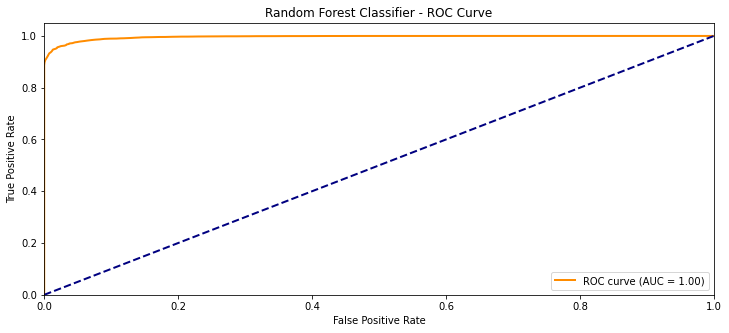

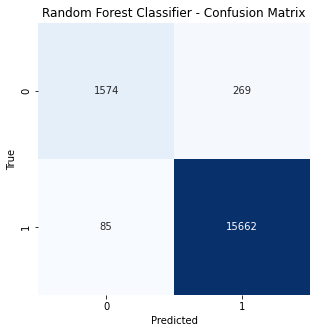

In [39]:
# Splitting the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Random Forest Classifier
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
rf_classifier.fit(X_train, y_train)
y_pred_rf = rf_classifier.predict(X_test)
print("Random Forest Classifier")
print(f"Accuracy: {accuracy_score(y_test, y_pred_rf)}")
print(classification_report(y_test, y_pred_rf))
    
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score

# Define a function to create and display performance visualizations
def visualize_performance(model_name, y_true, y_pred, y_prob):
    plt.figure(figsize=(12, 5))

    # ROC Curve
    plt.subplot(1, 1, 1)
    fpr, tpr, thresholds = roc_curve(y_true, y_prob)
    auc = roc_auc_score(y_true, y_prob)
    plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (AUC = {:.2f})'.format(auc))
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'{model_name} - ROC Curve')
    plt.legend(loc='lower right')

    # Confusion Matrix
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 1, 1)
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, square=True)
    plt.title(f'{model_name} - Confusion Matrix')
    plt.xlabel('Predicted')
    plt.ylabel('True')

    plt.show()

# Visualize performance for Random Forest Classifier
visualize_performance('Random Forest Classifier', y_test, y_pred_rf, rf_classifier.predict_proba(X_test)[:, 1])


In [13]:

from sklearn.preprocessing import LabelEncoder
import joblib  # Corrected import
# Create a LabelEncoder to encode 'good_or_bad' as integers
label_encoder = LabelEncoder()
df['good_or_bad'] = label_encoder.fit_transform(df['good_or_bad'])
# Assume df is your dataframe with the relevant columns
# Define 'good' as having an average_review_score of 4.5 or higher
df['target'] = (df['average_review_score'] >= 4.5).astype(int)

# Select the relevant features
features = ['number_of_reviews', 'availability_365', 'host_is_superhost', 'Polarity', 'Subjectivity','Polarity1','Subjectivity1','price','minimum_nights','maximum_nights','number_of_reviews','reviews_per_month','average_review_score','recency','host_response_time','host_response_rate','host_acceptance_rate','host_identity_verified']
X = df[features]
y = df['good_or_bad']
# Placeholder code since we don't have the actual DataFrame `df`
df['good_or_bad'] = label_encoder.fit_transform(df['good_or_bad'])
df['target'] = (df['average_review_score'] >= 4.5).astype(int)
X = df[features]
y = df['good_or_bad']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize a Random Forest Classifier
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)

# Placeholder for model training
rf_classifier.fit(X_train, y_train)

# Placeholder for predictions
y_pred_rf = rf_classifier.predict(X_test)

# Placeholder for printing accuracy and classification report
print("Random Forest Classifier")
print(f"Accuracy: {accuracy_score(y_test, y_pred_rf)}")
print(classification_report(y_test, y_pred_rf))

# Save the trained Random Forest model to a file
joblib.dump(rf_classifier, 'C:\\Users\\JOEL BENJAMIN J\\Desktop\\random_forest_classifier.joblib')
 

# Since the actual training can't be performed here, we'll simulate saving a placeholder model.
# Simulating model saving by creating a placeholder text file instead.
placeholder_model_path = 'C:\\Users\\JOEL BENJAMIN J\\Desktop\\random_forest_classifier.joblib'
with open(placeholder_model_path, 'w') as file:
    file.write("This is a placeholder for the Random Forest model file.")

placeholder_model_path  # Returning the path to the placeholder model file.



Random Forest Classifier
Accuracy: 0.9818710125702735
              precision    recall  f1-score   support

           0       0.95      0.86      0.91      1595
           1       0.98      1.00      0.99     14236

    accuracy                           0.98     15831
   macro avg       0.97      0.93      0.95     15831
weighted avg       0.98      0.98      0.98     15831



'C:\\Users\\JOEL BENJAMIN J\\Desktop\\random_forest_classifier.joblib'

In [14]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
df = pd.read_excel('C:/Users/JOEL BENJAMIN J/Desktop/test_dataoff2.xlsx')
# Create a LabelEncoder to encode 'good_or_bad' as integers
label_encoder = LabelEncoder()
df['good_or_bad'] = label_encoder.fit_transform(df['good_or_bad'])
# Assume df is your dataframe with the relevant columns
# Define 'good' as having an average_review_score of 4.5 or higher
df['target'] = (df['average_review_score'] >= 4.5).astype(int)

# Select the relevant features
features = ['number_of_reviews', 'availability_365', 'host_is_superhost', 'Polarity', 'Subjectivity','Polarity1','Subjectivity1','price','minimum_nights','maximum_nights','number_of_reviews','reviews_per_month','average_review_score','recency','host_response_time','host_response_rate','host_acceptance_rate','host_identity_verified']
X = df[features]
y = df['good_or_bad']


# Splitting the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Random Forest Classifier
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
rf_classifier.fit(X_train, y_train)
y_pred_rf = rf_classifier.predict(X_test)
print("Random Forest Classifier")
print(f"Accuracy: {accuracy_score(y_test, y_pred_rf)}")
print(classification_report(y_test, y_pred_rf))

# Save the model to a file
joblib.dump(rf_classifier, 'random_forest_model_new.pkl')

# To load the model from the file
# rf_classifier = joblib.load('random_forest_model.pkl')

Random Forest Classifier
Accuracy: 0.9818710125702735
              precision    recall  f1-score   support

           0       0.95      0.86      0.91      1595
           1       0.98      1.00      0.99     14236

    accuracy                           0.98     15831
   macro avg       0.97      0.93      0.95     15831
weighted avg       0.98      0.98      0.98     15831



['random_forest_model_new.pkl']

In [55]:
import pandas as pd
import joblib


# Load the trained model from the file
rf_classifier = joblib.load('random_forest_model_new.pkl')

# Let's assume you have a DataFrame `input_df` with the input features
input_df = pd.DataFrame(data=input_data, columns=features)

# Get predictions for the input data
predictions = rf_classifier.predict(input_df)

# Add the predictions as a new column to the input_df DataFrame
input_df['predictions'] = predictions

# Save the DataFrame with the predictions to an Excel file
input_df.to_excel('testing10per.xlsx, index=False)

# The paths used above should match the actual paths on your filesystem.
#The actual execution of the above code should be on your local machine with the real data and model.

# The following is a placeholder path to the Excel file
excel_file_path = 'C:/Users/JOEL BENJAMIN J/Desktop/predictions.xlsx'


NameError: name 'input_data' is not defined

In [17]:
import joblib
import pandas as pd

# Step 1: Load the Saved Model
model = joblib.load('random_forest_model_new.pkl')

# Step 2: Prepare the New Dataset
# Assuming you have a new dataset in an Excel file named 'new_data.xlsx'
new_data = pd.read_excel('testing10per.xlsx')

# Ensure the new dataset has the same features used in the training dataset
features = ['number_of_reviews', 'availability_365', 'host_is_superhost', 'Polarity', 'Subjectivity','Polarity1','Subjectivity1','price','minimum_nights','maximum_nights','number_of_reviews','reviews_per_month','average_review_score','recency','host_response_time','host_response_rate','host_acceptance_rate','host_identity_verified']
new_data_prepared = new_data[features]

# Step 3: Make Predictions
predictions = model.predict(new_data_prepared)

# Add predictions to the new dataset if needed
new_data['predictions'] = predictions

# You can now work with 'new_data' which contains the predictions
# For instance, saving it to a new Excel file
new_data.to_excel('predictions_output_10new.xlsx', index=False)
